# SEM basics · 8 — anisotropic and poroelastic rocks

Two equation families take more than `vp`, `vs` and `rho`:

1. **VTI and TTI** — `ElasticVTISEM2DDeformed`, an elastic solid with a vertical
   symmetry axis, described by the Thomsen parameters `epsilon` and `delta`, and
   `ElasticTTISEM2DDeformed`, which tilts the axis
2. **Biot** — `BiotVSSEM2DDeformed`, a porous solid filled with a fluid, described
   by eight coefficients; its pore fluid carries a second, slow P wave
3. **Biot options** — anisotropic permeability (`BiotAnisoPermSEM2DDeformed`),
   viscous attenuation (`equation_options`) and an attenuating frame
   (`ViscoBiotVSSEM2DDeformed`)

Both families run in 2-D on `impl='eager'` (Biot also in 3-D, see
[SEM basics · 7](../56_sem_3d/)). About two minutes on a GPU, most of it
compiling the eager steps.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from sweep.sem import PropSEM, thomsen_to_vti_cij
from sweep.sem.equations import (ElasticVSSEM2DDeformed, ElasticVTISEM2DDeformed,
                                 ElasticTTISEM2DDeformed, BiotVSSEM2DDeformed,
                                 BiotAnisoPermSEM2DDeformed, ViscoBiotVSSEM2DDeformed)
from sweep.equations.biot import biot_from_rock, biot_wave_velocities
from sweep.equations.biot_params import biot_drag_tensor
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

def crop(snap, solver):
    """(..., nz + pads, nx + pads) -> (..., nz, nx): drop the absorbing layer
    (every side absorbs in this notebook)."""
    a = solver.abcn
    return snap[..., a:snap.shape[-2] - a, a:snap.shape[-1] - a]

def show(ax, img, extent, title):
    v = np.percentile(np.abs(img), 99.5)
    ax.imshow(img, cmap='seismic', vmin=-v, vmax=v, extent=extent)
    ax.set_title(title); ax.set_xlabel('x (m)')

device: cuda


## 1. VTI

`ElasticVTISEM2DDeformed` is the velocity–stress elastic equation with a VTI
stress–strain law. Its models are the **vertical** P and S velocities, the
density and the two Thomsen parameters:

In [2]:
dh, f0, dt, nt = 2.5, 50.0, 1e-4, 1250
shape = (321, 321)                                        # 800 m x 800 m
vti = PropSEM(ElasticVTISEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=4,
              abcn=20, f_dominant=f0, source_type=['sxx', 'szz'],
              receiver_type=['vx', 'vz'], impl='eager', device=device)
print('model_names:', vti.model_names)
print('snapshot_fields:', vti.snapshot_fields)

model_names: ['vp', 'vs', 'rho', 'epsilon', 'delta']
snapshot_fields: ['v_x', 'v_z']


Internally the five models become four stiffnesses, `c11`, `c13`, `c33` and
`c55`. `thomsen_to_vti_cij` is the conversion the equation uses; `epsilon` makes
horizontal P faster than vertical P (`c11 = c33 (1 + 2 epsilon)`), and `delta`
sets `c13`, which controls P near the vertical:

In [3]:
vp, vs, rho, eps, delta = 3000.0, 1700.0, 2200.0, 0.25, 0.10
c11, c13, c33, c55 = thomsen_to_vti_cij(*(torch.tensor(v) for v in (vp, vs, eps, delta, rho)))
for name, c in zip(['c11', 'c13', 'c33', 'c55'], [c11, c13, c33, c55]):
    print(f'{name} = {float(c) / 1e9:6.2f} GPa')
print(f'P velocity: vertical {vp:.0f} m/s, horizontal {vp * (1 + 2 * eps) ** 0.5:.0f} m/s')

c11 =  29.70 GPa
c13 =   8.94 GPa
c33 =  19.80 GPa
c55 =   6.36 GPa
P velocity: vertical 3000 m/s, horizontal 3674 m/s


An explosion in the middle of a homogeneous model, once isotropic
(`epsilon = delta = 0`) and once VTI, with a 50 Hz wavelet. The snapshot shows
`v_z`. The dashed curves are the exact wavefronts after `t - t0` (`t0` is the
wavelet delay), computed from the stiffnesses: the group velocity of each wave
type, traced over all propagation directions. The helper below does that.

sweep: torch.compile is compiling the ElasticVTISEM2DDeformed step for a 321x321 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


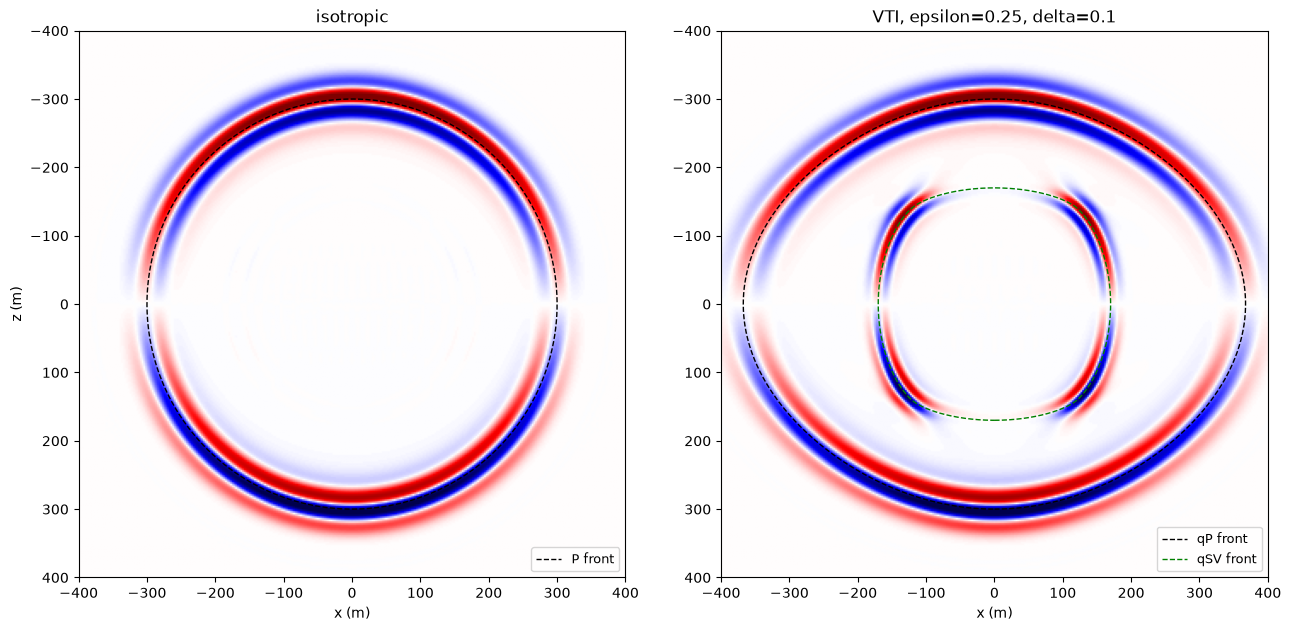

In [4]:
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[160, 160]])                                 # the centre
rx = np.arange(160, 321, 8)
rec = np.stack([rx, np.full_like(rx, 160)], axis=1)[None]    # a line to the right
k_snap = 1240

def wavefronts(eps, delta, t):
    """x, z of the qP and qSV fronts after time t (exact VTI phase velocity,
    turned into group velocity by v n + dv/dtheta dn/dtheta)."""
    c11, c13, c33, c55 = (float(c) for c in thomsen_to_vti_cij(
        *(torch.tensor(v, dtype=torch.float64) for v in (vp, vs, eps, delta, rho))))
    th = np.linspace(0, 2 * np.pi, 20001)
    sn, cs = np.sin(th), np.cos(th)
    a = (c11 + c55) * sn**2 + (c33 + c55) * cs**2
    b = np.sqrt(((c11 - c55) * sn**2 - (c33 - c55) * cs**2) ** 2
                + 4 * (c13 + c55) ** 2 * sn**2 * cs**2)
    out = {}
    for name, sign in [('qP', 1), ('qSV', -1)]:
        v = np.sqrt((a + sign * b) / (2 * rho))
        dv = np.gradient(v, th)
        out[name] = (t * (v * sn + dv * cs), t * (v * cs - dv * sn))
    return out

def run_vti(eps, delta):
    models = [torch.full(shape, v, device=device) for v in (vp, vs, rho, eps, delta)]
    with torch.no_grad():
        return vti(wavelet, src, rec, models=models,
                   return_wavefield=True, snapshot_times=[k_snap])

rec_iso, snap_iso = run_vti(0.0, 0.0)
rec_vti, snap_vti = run_vti(eps, delta)

t = k_snap * dt - 1.2 / f0
extent = [-400, 400, 400, -400]                              # source at (0, 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), constrained_layout=True)
for ax, snap, title, e, d in [(axes[0], snap_iso, 'isotropic', 0.0, 0.0),
                              (axes[1], snap_vti, f'VTI, epsilon={eps}, delta={delta}', eps, delta)]:
    show(ax, crop(snap, vti)[0, 1, 0, 0].cpu().numpy(), extent, title)
    fronts = wavefronts(e, d, t)
    ax.plot(*fronts['qP'], 'k--', lw=1, label='qP front' if e else 'P front')
    if e:
        ax.plot(*fronts['qSV'], '--', color='g', lw=1, label='qSV front')
    ax.legend(loc='lower right', fontsize=9)
axes[0].set_ylabel('z (m)')
plt.show()

The isotropic snapshot has a single wave, a circular P front. With VTI the qP
front is wider than tall: horizontally it travels at `vp sqrt(1 + 2 epsilon)`,
vertically at `vp`. Behind it there is a second wave, **qSV**, which an
explosion does not radiate in an isotropic solid. It is strongest at oblique
angles and vanishes along the axes, and its front is flattened at the top and
bottom rather than elliptical. Both simulated fronts sit on their curves.

`epsilon = delta = 0` gives back the isotropic velocity–stress equation. The
records agree with `ElasticVSSEM2DDeformed` on the same model to single-precision
rounding (the stiffnesses are computed in a different order):

In [5]:
iso = PropSEM(ElasticVSSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=4,
              abcn=20, f_dominant=f0, source_type=['sxx', 'szz'],
              receiver_type=['vx', 'vz'], impl='eager', device=device)
with torch.no_grad():
    rec_vs = iso(wavelet, src, rec,
                 models=[torch.full(shape, v, device=device) for v in (vp, vs, rho)])
print('relative difference: %.1e' % float((rec_iso - rec_vs).norm() / rec_vs.norm()))

sweep: torch.compile is compiling the ElasticVSSEM2DDeformed step for a 321x321 grid


relative difference: 4.6e-05


`epsilon` and `delta` are models like the others: give them `requires_grad=True`
and the backward pass returns their gradients (on eager, with the default
`Ckpt(chunks=8)`; see [SEM basics · 5](../54_sem_gradients_and_memory/)).

### Tilting the axis

`ElasticTTISEM2DDeformed` tilts the symmetry axis by a sixth model, `theta`
(radians). It rotates the VTI stiffnesses with the closed-form Bond rotation of
the FD `ElasticTTI2nd`, in its axes (z down) and with its sign of `theta`
(`thomsen_to_tti_cij` gives the six stiffnesses). The tilt couples the normal
stresses to the shear strain (`c15`, `c35`), and all six models are
differentiable. The same explosion with the axis tilted by 30 degrees; the
dashed curves are the VTI fronts of the right-hand panel above, rotated by
`theta`:

model_names: ['vp', 'vs', 'rho', 'epsilon', 'delta', 'theta']


sweep: torch.compile is compiling the ElasticTTISEM2DDeformed step for a 321x321 grid


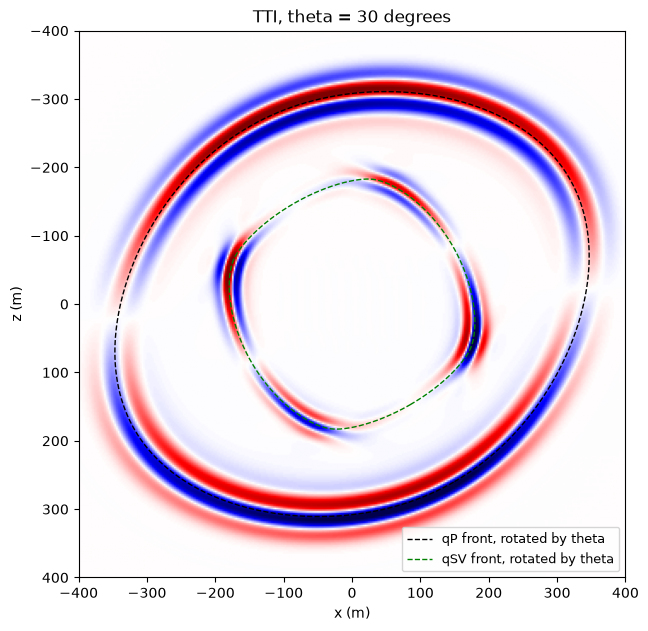

In [6]:
tti = PropSEM(ElasticTTISEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=4,
              abcn=20, f_dominant=f0, source_type=['sxx', 'szz'],
              receiver_type=['vx', 'vz'], impl='eager', device=device)
print('model_names:', tti.model_names)
theta = np.pi / 6                                              # 30 degrees
with torch.no_grad():
    rec_tti, snap_tti = tti(wavelet, src, rec,
                            models=[torch.full(shape, v, device=device)
                                    for v in (vp, vs, rho, eps, delta, theta)],
                            return_wavefield=True, snapshot_times=[k_snap])
fronts = wavefronts(eps, delta, t)
c, s = np.cos(theta), np.sin(theta)
fig, ax = plt.subplots(figsize=(6.6, 6.2), constrained_layout=True)
show(ax, crop(snap_tti, tti)[0, 1, 0, 0].cpu().numpy(), extent, 'TTI, theta = 30 degrees')
for name, color in [('qP', 'k'), ('qSV', 'g')]:
    x, z = fronts[name]
    ax.plot(c * x + s * z, -s * x + c * z, '--', color=color, lw=1,
            label=f'{name} front, rotated by theta')
ax.set_ylabel('z (m)'); ax.legend(loc='lower right', fontsize=9)
plt.show()

Both fronts turn with the axis. A positive `theta` tilts the axis from the
vertical towards +x as it goes down, so the plane of isotropy, along which qP is
fastest, rises towards +x. With `theta = 0` the class gives the VTI records to
single-precision round-off:

In [7]:
with torch.no_grad():
    rec_t0 = tti(wavelet, src, rec, models=[torch.full(shape, v, device=device)
                                            for v in (vp, vs, rho, eps, delta, 0.0)])
print('theta = 0 against ElasticVTISEM2DDeformed: relative difference %.1e'
      % float((rec_t0 - rec_vti).norm() / rec_vti.norm()))

theta = 0 against ElasticVTISEM2DDeformed: relative difference 4.5e-05


## 2. Biot

`BiotVSSEM2DDeformed` solves Biot's equations for a fluid-saturated porous
solid: the solid velocity `v`, the fluid flux relative to the solid `q` (Darcy
flux), the total stress and the pore pressure `p`. Its eight models are Biot's
coefficients `H, mu, C, M, rho, rho_f, m, b` (moduli in Pa, densities in kg/m^3,
`b` the viscous drag `eta / kappa`).

`biot_from_rock` builds them from rock and fluid properties: grain modulus and
density, fluid modulus, density and viscosity, dry-frame moduli, porosity,
permeability and tortuosity. Below, a sandstone saturated with water.
`biot_wave_velocities` returns the high-frequency speeds of the three waves:

In [8]:
rock = dict(k_s=36e9, rho_s=2650.0,                 # grains
            k_f=2.25e9, rho_f=1000.0, eta=1e-3,     # water
            k_d=9e9, mu=7e9, phi=0.25, tortuosity=2.0)

def coefficients(kappa):
    return biot_from_rock(kappa=kappa, **rock)

names = ['H', 'mu', 'C', 'M', 'rho', 'rho_f', 'm', 'b']
for n, c in zip(names, coefficients(1e-8)):
    print(f'{n:6s} {float(c):10.3e}')
v_fast, v_slow, v_s = (float(v) for v in biot_wave_velocities(coefficients(1e-8)))
print(f'fast P {v_fast:.0f} m/s, slow P {v_slow:.0f} m/s, S {v_s:.0f} m/s')

H       2.283e+10
mu      7.000e+09
C       6.000e+09
M       8.000e+09
rho     2.238e+03
rho_f   1.000e+03
m       8.000e+03
b       1.000e+05
fast P 3212 m/s, slow P 917 m/s, S 1820 m/s


The slow P wave is the fluid moving against the solid. Whether it propagates
depends on the frequency relative to Biot's characteristic frequency
`f_c = eta phi / (2 pi rho_f kappa T)`: above `f_c` (high permeability) it
propagates at the speed above; below it the viscous drag turns it into a
diffusion that stays near the source. The permeability `kappa` enters only the
last coefficient, `b = eta / kappa`.

An explosion in a homogeneous rock with `kappa = 1e-8 m^2`, where `f_c` is about
2 Hz, well below the 40 Hz wavelet. The model is 320 m wide on 2 m cells (8 m
elements); the time step follows the fast P wave:

snapshot_fields: ['v_x', 'v_z', 'p']  memory: ckpt
f_c = 2.0 Hz


sweep: torch.compile is compiling the BiotVSSEM2DDeformed step for a 161x161 grid


record (1, 700, 20, 3) (shots, nt, receivers, [vx, vz, p])


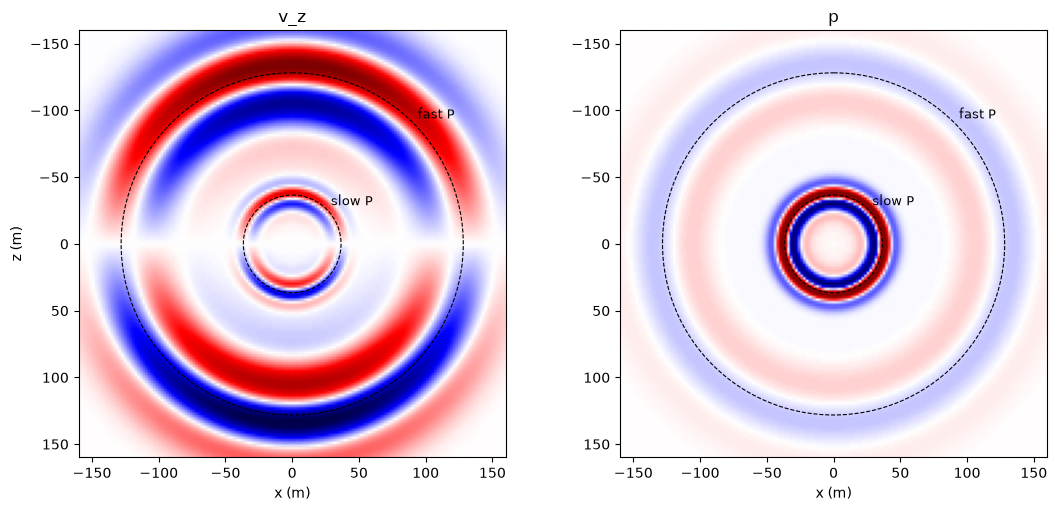

In [9]:
dh_b, f0_b, dt_b, nt_b = 2.0, 40.0, 1e-4, 700
shape_b = (161, 161)
wavelet_b = ricker(np.arange(nt_b) * dt_b - 1.2 / f0_b, f=f0_b).astype(np.float32)
src_b = np.array([[80, 80]])                                     # the centre
rz = np.arange(84, 161, 4)
rec_b = np.stack([np.full_like(rz, 80), rz], axis=1)[None]       # a line below

def f_c(kappa):
    return rock['eta'] * rock['phi'] / (2 * np.pi * rock['rho_f'] * kappa * rock['tortuosity'])

def biot_solver(equation=BiotVSSEM2DDeformed, **kw):
    return PropSEM(equation, shape=shape_b, dh=dh_b, dt=dt_b, n_order=4, abcn=20,
                   f_dominant=f0_b, source_type=['sxx', 'szz'],
                   receiver_type=['vx', 'vz', 'p'], impl='eager', device=device, **kw)

def run_biot(solver, coef, nt=nt_b):
    models = [torch.full(shape_b, float(c), device=device) for c in coef]
    with torch.no_grad():
        return solver(wavelet_b[:nt], src_b, rec_b, models=models,
                      return_wavefield=True, snapshot_times=[nt - 1])

biot = biot_solver()
print('snapshot_fields:', biot.snapshot_fields, ' memory:', biot.memory_strategy)
print('f_c = %.1f Hz' % f_c(1e-8))
rec_fast, snap_fast = run_biot(biot, coefficients(1e-8))
print('record', tuple(rec_fast.shape), '(shots, nt, receivers, [vx, vz, p])')

t = (nt_b - 1) * dt_b - 1.2 / f0_b
extent_b = [-160, 160, 160, -160]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, f, title in [(axes[0], 1, 'v_z'), (axes[1], 2, 'p')]:
    show(ax, crop(snap_fast, biot)[0, f, 0, 0].cpu().numpy(), extent_b, title)
    for v, label in [(v_fast, 'fast P'), (v_slow, 'slow P')]:
        ax.add_patch(Circle((0, 0), v * t, fill=False, ls='--', color='k', lw=0.8))
        ax.text(v * t * 0.71 + 3, -v * t * 0.71 - 3, label, fontsize=9)
axes[0].set_ylabel('z (m)')
plt.show()

Both P waves are on their circles and show in both fields. In the pore
pressure the slow wave is much the stronger: it is the fluid moving against the
solid, while in the fast wave the two move together. An explosion radiates no S wave
in an isotropic rock.

The record holds one trace per receiver and name; `receiver_type` takes `vx`,
`vz`, `p`, `qx`, `qz`, `sxx`, `szz` and `sxz`, and `source_type` the stress pair
(an explosion, as here), `sxz`, a force `fx`/`fz` on solid and fluid, `p`, a
solid velocity or a flux. The [SEM user guide](../../user-guide/sem/#poroelastic-waves-biot)
lists what each source drives.

## 3. Permeability and the Biot options

Lowering the permeability to `kappa = 1e-10 m^2` raises `f_c` above the source
band, and the slow wave stops propagating. With a permeability **tensor** it
can propagate in one direction and diffuse in another:
`BiotAnisoPermSEM2DDeformed` replaces the scalar `b` by the three components of
`eta kappa^-1`, which `biot_drag_tensor(eta, k_xx, k_xz, k_zz)` gives (x right,
z down). Here `k_xx = 1e-8` and `k_zz = 1e-10`:

f_c(1e-10) = 199 Hz


BiotAnisoPermSEM2DDeformed models: ['H', 'mu', 'C', 'M', 'rho', 'rho_f', 'm', 'b_xx', 'b_xz', 'b_zz']


sweep: torch.compile is compiling the BiotAnisoPermSEM2DDeformed step for a 161x161 grid


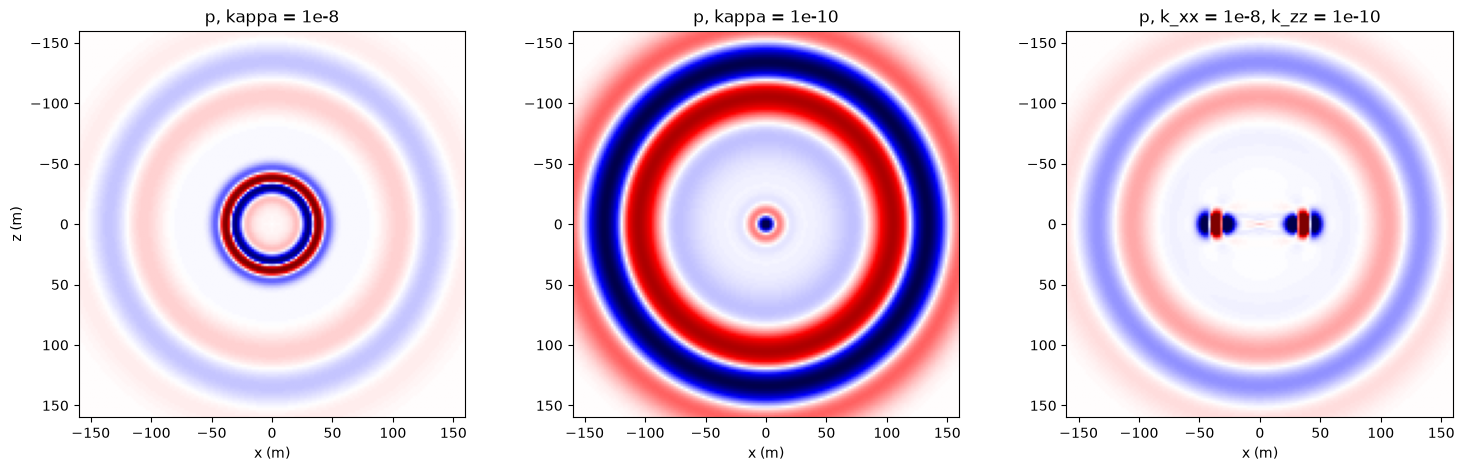

In [10]:
print('f_c(1e-10) = %.0f Hz' % f_c(1e-10))
_, snap_tight = run_biot(biot, coefficients(1e-10))

aniso = biot_solver(BiotAnisoPermSEM2DDeformed)
print('BiotAnisoPermSEM2DDeformed models:', aniso.model_names)
b_tensor = biot_drag_tensor(rock['eta'], 1e-8, 0.0, 1e-10)
_, snap_aniso = run_biot(aniso, coefficients(1e-8)[:7] + list(b_tensor))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, snap, solver, title in [
        (axes[0], snap_fast, biot, 'kappa = 1e-8'),
        (axes[1], snap_tight, biot, 'kappa = 1e-10'),
        (axes[2], snap_aniso, aniso, 'k_xx = 1e-8, k_zz = 1e-10')]:
    show(ax, crop(snap, solver)[0, 2, 0, 0].cpu().numpy(), extent_b, 'p, ' + title)
axes[0].set_ylabel('z (m)')
plt.show()

With the low permeability the slow wave is a small diffusive blob at the source
and the fast P wave carries almost all the pressure. With the tensor, the slow
wave travels horizontally, where the permeability is high, and not vertically.
Each panel has its own colour scale.

### `equation_options`

Options of an equation's own `build` go through `equation_options`. Biot's
`viscous_q=(Q0, f0)` makes the drag frequency dependent (a standard linear
solid with quality factor `Q0` at `f0`), which mainly changes the slow wave.
At `kappa = 1e-9` (`f_c` about 20 Hz, inside the source band) we compare the
pore pressure 64 m below the source with and without it. The grey lines mark the
arrival times at the high-frequency speeds:

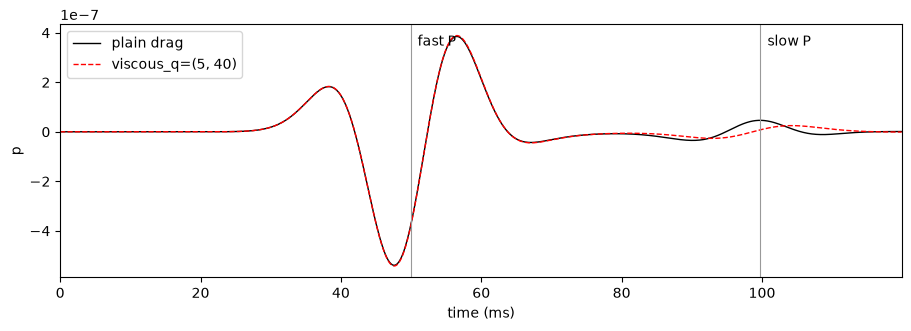

In [11]:
nt_q = 1200
wavelet_b = ricker(np.arange(nt_q) * dt_b - 1.2 / f0_b, f=f0_b).astype(np.float32)
rec_plain, _ = run_biot(biot, coefficients(1e-9), nt_q)
viscous = biot_solver(equation_options={'viscous_q': (5.0, 40.0)})
rec_visc, _ = run_biot(viscous, coefficients(1e-9), nt_q)

ir = 7
dist = (rz[ir] - src_b[0, 1]) * dh_b         # 64 m below the source
tt = np.arange(nt_q) * dt_b * 1e3
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.plot(tt, rec_plain[0, :, ir, 2].cpu(), 'k', lw=1, label='plain drag')
ax.plot(tt, rec_visc[0, :, ir, 2].cpu(), 'r--', lw=1, label="viscous_q=(5, 40)")
for v, label in [(v_fast, 'fast P'), (v_slow, 'slow P')]:
    ta = (dist / v + 1.2 / f0_b) * 1e3
    ax.axvline(ta, color='0.6', lw=0.8); ax.text(ta + 1, ax.get_ylim()[1] * 0.8, label)
ax.set_xlabel('time (ms)'); ax.set_ylabel('p'); ax.set_xlim(0, tt[-1]); ax.legend()
plt.show()

The fast P arrival is unchanged. With the plain drag the slow wave arrives on
time; the viscous drag delays and weakens it.
A name the equation does not take is refused, with the names it does take:

In [12]:
try:
    biot_solver(equation_options={'viscous': (5.0, 40.0)})
except TypeError as err:
    print('TypeError:', err)

TypeError: equation_options ['viscous'] are not options of BiotVSSEM2DDeformed.build; it takes ['viscous_q']


### Frame attenuation

`ViscoBiotVSSEM2DDeformed` attenuates the frame with the standard linear solids
of the visco-elastic velocity–stress class (see
[Attenuation · nonlinear Q fit, attenuating C-PML](../49_sem_attenuation/)). Two
more models, `Qp` and `Qs`, act on the drained P modulus `H - C^2 / M` and on
`mu`; the fluid's share of `H` does not relax, and the drag is unchanged.
`equation_options` take `f_ref` (the frequency at which `H` and `mu` are the given
moduli), `f_band` and `n_sls`. Like the drag, the attenuation cannot be stepped
backward, so boundary saving is refused. The rock with `kappa = 1e-8 m^2` again,
with `Qp = Qs = 20` and with the elastic frame, at the receiver 64 m below the
source:

models: ['H', 'mu', 'C', 'M', 'rho', 'rho_f', 'm', 'b', 'Qp', 'Qs']


sweep: torch.compile is compiling the ViscoBiotVSSEM2DDeformed step for a 161x161 grid


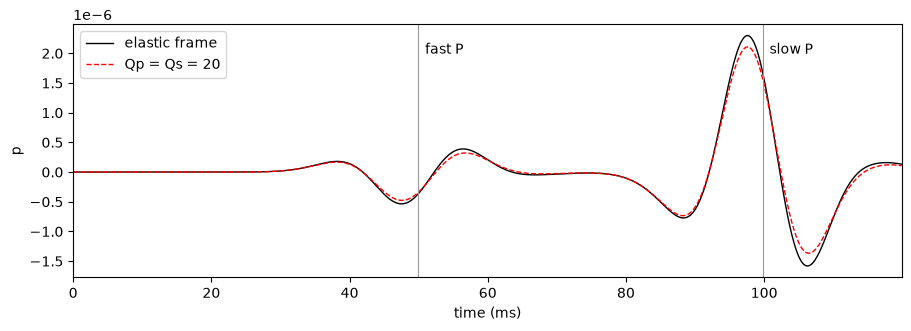

fast P: peak |p| with Q = 20 / elastic frame = 0.890
slow P: peak |p| with Q = 20 / elastic frame = 0.917


In [13]:
visco = biot_solver(ViscoBiotVSSEM2DDeformed, equation_options={'f_ref': f0_b})
print('models:', visco.model_names)
coef = [float(c) for c in coefficients(1e-8)]
rec_frame, _ = run_biot(biot, coef, nt_q)
rec_q, _ = run_biot(visco, coef + [20.0, 20.0], nt_q)
p_frame = rec_frame[0, :, ir, 2].cpu().numpy()
p_q = rec_q[0, :, ir, 2].cpu().numpy()

fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.plot(tt, p_frame, 'k', lw=1, label='elastic frame')
ax.plot(tt, p_q, 'r--', lw=1, label='Qp = Qs = 20')
for v, label in [(v_fast, 'fast P'), (v_slow, 'slow P')]:
    ta = (dist / v + 1.2 / f0_b) * 1e3
    ax.axvline(ta, color='0.6', lw=0.8); ax.text(ta + 1, ax.get_ylim()[1] * 0.8, label)
ax.set_xlabel('time (ms)'); ax.set_ylabel('p'); ax.set_xlim(0, tt[-1]); ax.legend()
plt.show()
for name, lo, hi in [('fast P', 25, 75), ('slow P', 80, 125)]:
    w = (tt > lo) & (tt < hi)
    print(f'{name}: peak |p| with Q = 20 / elastic frame = '
          f'{np.abs(p_q[w]).max() / np.abs(p_frame[w]).max():.3f}')

Both P waves lose amplitude over the 64 m, the fast one 11% of its peak pore
pressure and the slow one 8%, and their arrival times hardly move: `f_ref` is the
source's centre frequency, at which the frame's moduli are the given `H` and `mu`.

## Summary

| | VTI and TTI | Biot |
| --- | --- | --- |
| equation | `ElasticVTISEM2DDeformed`, `ElasticTTISEM2DDeformed` | `BiotVSSEM2DDeformed`, `BiotAnisoPermSEM2DDeformed`, `ViscoBiotVSSEM2DDeformed` |
| models | `vp`, `vs` (vertical), `rho`, `epsilon`, `delta` (TTI: and `theta`) | `H, mu, C, M, rho, rho_f, m, b` (or `b_xx, b_xz, b_zz`; with frame attenuation and `Qp, Qs`) |
| helpers | `thomsen_to_vti_cij`, `thomsen_to_tti_cij` | `biot_from_rock`, `biot_wave_velocities`, `biot_drag_tensor` |
| backend | eager, 2-D | eager, 2-D (and `BiotVSSEM3DDeformed` in 3-D) |
| memory | `Ckpt` (default), `Full`, `BoundarySaving` | `Ckpt` (default), `Full`; boundary saving is refused, since the drag and the attenuation cannot be stepped backward |

Biot models can also mix fluid, porous and dry elastic regions in one mesh
(`biot_fluid`, `biot_elastic` in `sweep.equations.biot_params`), with the
interfaces on element edges as in
[SEM basics · 6](../55_sem_fluid_solid/); see the
[SEM user guide](../../user-guide/sem/#fluid-and-dry-elastic-regions).

---

<p><strong>Download this notebook</strong> &mdash; <a href="57_sem_vti_and_biot.ipynb" download><code>57_sem_vti_and_biot.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/57_sem_vti_and_biot.ipynb">view on GitHub</a></p>